# Hashing Vectorization in NLP: Implementation with Python & Scikit-Learn

This notebook accompanies `theory.md` and covers:

1. The hashing trick implemented **from scratch**
2. `HashingVectorizer` in scikit-learn (and verifying our scratch version matches it)
3. Key parameters (`n_features`, `alternate_sign`, `norm`, `binary`, `ngram_range`)
4. Hash collisions and how `n_features` affects them
5. Comparison with `CountVectorizer` (memory and vocabulary)
6. Hashing + TF-IDF
7. Text classification pipeline
8. Out-of-core / streaming learning with `partial_fit`

In [1]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

from scipy import sparse
from sklearn.feature_extraction.text import (
    HashingVectorizer, CountVectorizer, TfidfTransformer, TfidfVectorizer
)
from sklearn.feature_extraction import FeatureHasher
from sklearn.utils import murmurhash3_32
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

np.set_printoptions(linewidth=120)
pd.set_option("display.width", 140)

## 1. A small corpus

In [2]:
docs = [
    "The cat sat on the mat",
    "The dog sat on the log",
    "Cats and dogs are great pets",
    "Machine learning turns text into numbers",
    "Hashing turns words into column indices",
]
for i, d in enumerate(docs):
    print(i, d)

0 The cat sat on the mat
1 The dog sat on the log
2 Cats and dogs are great pets
3 Machine learning turns text into numbers
4 Hashing turns words into column indices


## 2. The hashing trick from scratch

Core idea:

```
index = |hash(token)| mod n_features
sign  = +1 if hash(token) >= 0 else -1
```

We use **MurmurHash3** (the same one scikit-learn uses). Python's built-in `hash()` is randomized per process for strings, so it is not suitable.

In [3]:
def hash_token(token, n_features, alternate_sign=True):
    h = murmurhash3_32(token, seed=0, positive=False)   # signed 32-bit int
    index = abs(h) % n_features
    sign = (1 if h >= 0 else -1) if alternate_sign else 1
    return index, sign

n_features = 8
for tok in ["cat", "sat", "mat", "dog", "hashing"]:
    print(f"{tok:8s} -> {hash_token(tok, n_features)}")

cat      -> (7, 1)
sat      -> (4, 1)
mat      -> (3, -1)
dog      -> (5, -1)
hashing  -> (3, -1)


In [4]:
def simple_tokenize(text):
    # Mimics HashingVectorizer's default: lowercase + tokens of 2+ word characters
    import re
    return re.findall(r"(?u)\b\w\w+\b", text.lower())

def hashing_vectorize(docs, n_features=16, alternate_sign=True):
    rows, cols, vals = [], [], []
    for r, doc in enumerate(docs):
        bucket = defaultdict(float)
        for tok in simple_tokenize(doc):
            idx, sign = hash_token(tok, n_features, alternate_sign)
            bucket[idx] += sign
        for idx, v in bucket.items():
            rows.append(r); cols.append(idx); vals.append(v)
    return sparse.csr_matrix((vals, (rows, cols)), shape=(len(docs), n_features))

X_scratch = hashing_vectorize(docs, n_features=16)
print(X_scratch.toarray())

[[ 0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0. -1.  0.  0. -2.  0.]
 [ 0.  0.  0.  0.  1. -1.  0. -1.  0.  0.  0.  0.  0.  0. -1.  0.]
 [ 1.  0. -1.  0.  0.  0.  0. -1.  0.  0.  0.  0.  1.  0.  0.  0.]
 [-1.  0.  1.  0.  0. -2.  0.  0.  0.  0.  0.  0. -1.  0.  0. -1.]
 [ 0.  0.  0.  0.  1. -1.  0.  0.  0.  0. -1. -1.  0.  0.  0.  0.]]


## 3. Scikit-learn's `HashingVectorizer`

With `norm=None` we get raw (signed) counts, so we can check that our scratch version reproduces scikit-learn exactly.

In [5]:
hv = HashingVectorizer(n_features=16, norm=None, alternate_sign=True)
X_sk = hv.transform(docs)

print("type :", type(X_sk))
print("shape:", X_sk.shape, "| nnz:", X_sk.nnz)
print(X_sk.toarray())
print()
print("Scratch implementation matches scikit-learn:",
      np.array_equal(X_scratch.toarray(), X_sk.toarray()))

type : <class 'scipy.sparse._csr.csr_matrix'>
shape: (5, 16) | nnz: 23
[[ 0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0. -1.  0.  0. -2.  0.]
 [ 0.  0.  0.  0.  1. -1.  0. -1.  0.  0.  0.  0.  0.  0. -1.  0.]
 [ 1.  0. -1.  0.  0.  0.  0. -1.  0.  0.  0.  0.  1.  0.  0.  0.]
 [-1.  0.  1.  0.  0. -2.  0.  0.  0.  0.  0.  0. -1.  0.  0. -1.]
 [ 0.  0.  0.  0.  1. -1.  0.  0.  0.  0. -1. -1.  0.  0.  0.  0.]]

Scratch implementation matches scikit-learn: True


### Notes

- `fit()` does nothing: the vectorizer is **stateless**. You can call `transform()` directly.
- Output is a sparse CSR matrix.
- Some entries are negative because `alternate_sign=True`.

## 4. Key parameters

### 4.1 `alternate_sign` and `norm`

In [6]:
for kwargs in [
    dict(alternate_sign=True,  norm=None),
    dict(alternate_sign=False, norm=None),
    dict(alternate_sign=False, norm="l1"),
    dict(alternate_sign=False, norm="l2"),
]:
    v = HashingVectorizer(n_features=16, **kwargs)
    print(kwargs)
    print(np.round(v.transform(docs[:2]).toarray(), 2), "\n")

{'alternate_sign': True, 'norm': None}
[[ 0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0. -1.  0.  0. -2.  0.]
 [ 0.  0.  0.  0.  1. -1.  0. -1.  0.  0.  0.  0.  0.  0. -1.  0.]] 

{'alternate_sign': False, 'norm': None}
[[0. 0. 0. 0. 1. 0. 0. 2. 0. 0. 0. 1. 0. 0. 2. 0.]
 [0. 0. 0. 0. 1. 1. 0. 1. 0. 0. 0. 0. 0. 0. 3. 0.]] 

{'alternate_sign': False, 'norm': 'l1'}
[[0.   0.   0.   0.   0.17 0.   0.   0.33 0.   0.   0.   0.17 0.   0.   0.33 0.  ]
 [0.   0.   0.   0.   0.17 0.17 0.   0.17 0.   0.   0.   0.   0.   0.   0.5  0.  ]] 

{'alternate_sign': False, 'norm': 'l2'}
[[0.   0.   0.   0.   0.32 0.   0.   0.63 0.   0.   0.   0.32 0.   0.   0.63 0.  ]
 [0.   0.   0.   0.   0.29 0.29 0.   0.29 0.   0.   0.   0.   0.   0.   0.87 0.  ]] 



### 4.2 `binary` and `ngram_range`

In [7]:
sentence = ["to be or not to be"]

v_counts = HashingVectorizer(n_features=32, norm=None, alternate_sign=False)
v_binary = HashingVectorizer(n_features=32, norm=None, alternate_sign=False, binary=True)
print("counts:", v_counts.transform(sentence).toarray()[0])
print("binary:", v_binary.transform(sentence).toarray()[0])

v_bi = HashingVectorizer(n_features=2**10, norm=None, alternate_sign=False, ngram_range=(1, 2))
print("\nunigrams only nnz:", v_counts.transform(sentence).nnz)
print("uni+bigrams  nnz:", v_bi.transform(sentence).nnz)
print("analyzer output :", v_bi.build_analyzer()(sentence[0]))

counts: [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 2. 0. 0. 2. 0.]
binary: [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0.]

unigrams only nnz: 4
uni+bigrams  nnz: 8
analyzer output : ['to', 'be', 'or', 'not', 'to', 'be', 'to be', 'be or', 'or not', 'not to', 'to be']


### 4.3 Character n-grams (useful for typos and morphologically rich languages)

In [8]:
v_char = HashingVectorizer(analyzer="char_wb", ngram_range=(3, 4),
                           n_features=2**12, norm="l2", alternate_sign=False)
Xc = v_char.transform(["hashing", "hashes", "banana"])
sim = (Xc @ Xc.T).toarray()
print(pd.DataFrame(np.round(sim, 2), index=["hashing", "hashes", "banana"],
                   columns=["hashing", "hashes", "banana"]))

         hashing  hashes  banana
hashing     1.00    0.42     0.0
hashes      0.42    1.00     0.0
banana      0.00    0.00     1.0


## 5. Hash collisions

Different tokens can land in the same bucket. Let's measure how often that happens as `n_features` changes, using a few thousand synthetic distinct tokens.

In [9]:
rng = np.random.default_rng(42)
alphabet = list("abcdefghijklmnopqrstuvwxyz")
tokens = {"".join(rng.choice(alphabet, size=rng.integers(4, 9))) for _ in range(5000)}
tokens = sorted(tokens)
print("distinct tokens:", len(tokens))

def collision_stats(tokens, n_features):
    buckets = defaultdict(list)
    for t in tokens:
        buckets[hash_token(t, n_features)[0]].append(t)
    used = len(buckets)
    # tokens that share a bucket with at least one other token
    colliding = sum(len(v) for v in buckets.values() if len(v) > 1)
    return used, colliding / len(tokens)

rows = []
for p in range(10, 21):
    nf = 2 ** p
    used, frac = collision_stats(tokens, nf)
    rows.append((nf, used, frac))
coll = pd.DataFrame(rows, columns=["n_features", "buckets_used", "frac_tokens_colliding"])
coll

distinct tokens: 4998


,n_features,buckets_used,frac_tokens_colliding
0,1024,1019,0.994198
1,2048,1881,0.910964
2,4096,2900,0.700680
3,8192,3700,0.469788
4,16384,4271,0.278311
5,32768,4602,0.154862
6,65536,4789,0.082833
7,131072,4881,0.046218
8,262144,4940,0.023009
9,524288,4972,0.010404


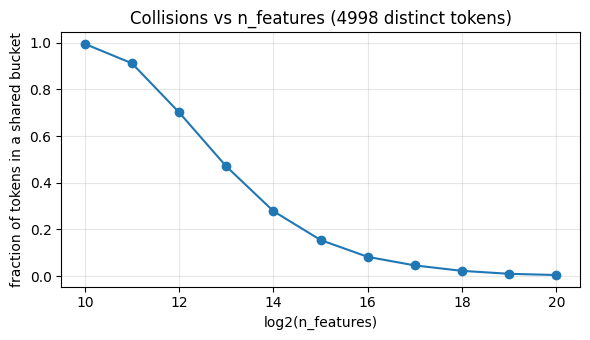

In [10]:
plt.figure(figsize=(6, 3.5))
plt.plot(np.log2(coll.n_features), coll.frac_tokens_colliding, marker="o")
plt.xlabel("log2(n_features)")
plt.ylabel("fraction of tokens in a shared bucket")
plt.title(f"Collisions vs n_features ({len(tokens)} distinct tokens)")
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()

### Does signed hashing preserve similarity?

With `alternate_sign=True`, the inner product in the hashed space is an **unbiased estimate** of the inner product in the original space. We can check this with a tiny `n_features`, where collisions are heavy.

In [11]:
texts = [
    "the quick brown fox jumps over the lazy dog near the river bank",
    "a quick brown dog jumps over the lazy fox near the old river",
    "stock markets fell sharply as investors worried about inflation rates",
    "central banks raised interest rates to fight rising inflation",
]

# "True" similarity from a full vocabulary
cv = CountVectorizer()
Xtrue = cv.fit_transform(texts).astype(float)
Xtrue = sparse.csr_matrix(Xtrue.multiply(1 / sparse.linalg.norm(Xtrue, axis=1)[:, None]))
true_sim = (Xtrue @ Xtrue.T).toarray()

def hashed_sim(nf, signed):
    v = HashingVectorizer(n_features=nf, alternate_sign=signed, norm="l2")
    Xh = v.transform(texts)
    return (Xh @ Xh.T).toarray()

for nf in [16, 64, 2**14]:
    for signed in [False, True]:
        err = np.abs(hashed_sim(nf, signed) - true_sim).mean()
        print(f"n_features={nf:6d} signed={signed!s:5}  mean abs error vs true similarity = {err:.3f}")

n_features=    16 signed=False  mean abs error vs true similarity = 0.385
n_features=    16 signed=True   mean abs error vs true similarity = 0.134
n_features=    64 signed=False  mean abs error vs true similarity = 0.250
n_features=    64 signed=True   mean abs error vs true similarity = 0.135
n_features= 16384 signed=False  mean abs error vs true similarity = 0.000
n_features= 16384 signed=True   mean abs error vs true similarity = 0.000


## 6. `HashingVectorizer` vs `CountVectorizer`: memory and vocabulary

`CountVectorizer` stores a `vocabulary_` dict; `HashingVectorizer` stores nothing. We generate a larger synthetic corpus to see the difference.

In [12]:
rng = np.random.default_rng(0)
vocab_size = 50_000
words = np.array([f"w{i}" for i in range(vocab_size)])
# Zipf-like word frequencies
p = 1 / np.arange(1, vocab_size + 1); p /= p.sum()

def make_doc(n_words=40):
    return " ".join(rng.choice(words, size=n_words, p=p))

big_docs = [make_doc() for _ in range(5000)]
print("example:", big_docs[0][:80], "...")

example: w797 w11 w0 w0 w5952 w18498 w564 w2290 w274 w23855 w6130 w0 w9843 w0 w2294 w3 w1 ...


In [13]:
def dict_size_bytes(d):
    # rough size of dict + its keys and values
    return sys.getsizeof(d) + sum(sys.getsizeof(k) + sys.getsizeof(v) for k, v in d.items())

t0 = time.perf_counter()
cv = CountVectorizer(token_pattern=r"\w+")
X_cv = cv.fit_transform(big_docs)
t_cv = time.perf_counter() - t0

t0 = time.perf_counter()
hv = HashingVectorizer(n_features=2**18, token_pattern=r"\w+", alternate_sign=False, norm=None)
X_hv = hv.transform(big_docs)
t_hv = time.perf_counter() - t0

print(f"CountVectorizer   : shape={X_cv.shape}, time={t_cv:.2f}s, "
      f"vocab dict ~= {dict_size_bytes(cv.vocabulary_)/1e6:.1f} MB")
print(f"HashingVectorizer : shape={X_hv.shape}, time={t_hv:.2f}s, vocab dict = none (0 MB)")
print(f"\nnnz  CV={X_cv.nnz:,}  HV={X_hv.nnz:,}  (HV lower because colliding words merge)")

CountVectorizer   : shape=(5000, 28495), time=0.33s, vocab dict ~= 3.7 MB
HashingVectorizer : shape=(5000, 262144), time=0.17s, vocab dict = none (0 MB)

nnz  CV=172,842  HV=172,835  (HV lower because colliding words merge)


**Interpretation**

- `CountVectorizer` needs a vocabulary that grows with the data (here ~50k entries, millions in real corpora).
- `HashingVectorizer` has a fixed number of columns and no stored vocabulary.
- You *can* ask `CountVectorizer` for feature names. You *cannot* ask `HashingVectorizer`, because hashing is one-way.

In [14]:
print("CountVectorizer feature names:", cv.get_feature_names_out()[:5])
print("HashingVectorizer has get_feature_names_out?", hasattr(hv, "get_feature_names_out"))

CountVectorizer feature names: ['w0' 'w1' 'w10' 'w100' 'w1000']
HashingVectorizer has get_feature_names_out? False


## 7. Adding TF-IDF on top of hashing

`HashingVectorizer` has no IDF. If you want it, combine with `TfidfTransformer`. This reintroduces a small fitted state (one IDF weight per column), but not a vocabulary.

In [15]:
hv_raw = HashingVectorizer(n_features=2**12, alternate_sign=False, norm=None)
tfidf = TfidfTransformer()                       # fits IDF over the hashed columns
X_tfidf = tfidf.fit_transform(hv_raw.transform(docs))
print(X_tfidf.shape, "| idf vector length:", tfidf.idf_.shape)

# equivalent one-liner as a pipeline
hash_tfidf = make_pipeline(
    HashingVectorizer(n_features=2**12, alternate_sign=False, norm=None),
    TfidfTransformer(),
)
print(np.allclose(hash_tfidf.fit_transform(docs).toarray(), X_tfidf.toarray()))

(5, 4096) | idf vector length: (4096,)
True


## 8. Text classification with hashing

A small template-generated sentiment dataset keeps the notebook self-contained (no downloads). Real use would be a much larger, real corpus.

In [16]:
rng = np.random.default_rng(7)
pos_w = "great fantastic wonderful brilliant superb delightful lovely excellent enjoyable charming".split()
neg_w = "terrible awful boring dreadful poor tedious dull disappointing painful mediocre".split()
nouns = "movie film story script cast soundtrack ending performance direction plot".split()
neutral = "the this a really quite overall honestly I thought it was and with its".split()
templates = [
    "{n1} {a} {n2} and a {b} {n3}",
    "I thought the {n1} was {a} and the {n2} was {b}",
    "overall a {a} {n1} with a {b} {n2}",
    "honestly this {n1} felt {a}, the {n2} was {b}",
]

def make_review(label):
    words = pos_w if label else neg_w
    t = templates[rng.integers(len(templates))]
    return t.format(n1=rng.choice(nouns), n2=rng.choice(nouns), n3=rng.choice(nouns),
                    a=rng.choice(words), b=rng.choice(words))

y = rng.integers(0, 2, size=600)
texts_all = [make_review(l) for l in y]
for t, l in list(zip(texts_all, y))[:4]:
    print(l, "|", t)

X_tr, X_te, y_tr, y_te = train_test_split(texts_all, y, test_size=0.3, random_state=7, stratify=y)
print(len(X_tr), "train /", len(X_te), "test")

1 | I thought the ending was enjoyable and the film was excellent
1 | overall a wonderful performance with a superb script
1 | script superb script and a great cast
1 | I thought the direction was fantastic and the cast was brilliant
420 train / 180 test


In [17]:
clf = make_pipeline(
    HashingVectorizer(n_features=2**14, ngram_range=(1, 2), alternate_sign=True, norm="l2"),
    LogisticRegression(max_iter=1000),
)
clf.fit(X_tr, y_tr)
pred = clf.predict(X_te)
print("accuracy:", accuracy_score(y_te, pred))
print(classification_report(y_te, pred, target_names=["neg", "pos"]))

for s in ["a fantastic and enjoyable film", "boring, awful and a waste", "never seen before words zxqv blorp"]:
    print(f"{s!r:45} -> {'pos' if clf.predict([s])[0] else 'neg'}")

accuracy: 1.0
              precision    recall  f1-score   support

         neg       1.00      1.00      1.00        85
         pos       1.00      1.00      1.00        95

    accuracy                           1.00       180
   macro avg       1.00      1.00      1.00       180
weighted avg       1.00      1.00      1.00       180

'a fantastic and enjoyable film'              -> pos
'boring, awful and a waste'                   -> neg
'never seen before words zxqv blorp'          -> pos


Note the last example: unseen words (`zxqv`, `blorp`) still get hashed to *some* bucket, so nothing crashes, though they carry no learned signal.

### Naive Bayes needs non-negative features

In [18]:
nb_pipe = make_pipeline(
    HashingVectorizer(n_features=2**14, alternate_sign=False, norm=None),   # non-negative counts
    MultinomialNB(),
)
nb_pipe.fit(X_tr, y_tr)
print("MultinomialNB accuracy:", accuracy_score(y_te, nb_pipe.predict(X_te)))

try:
    bad = make_pipeline(HashingVectorizer(n_features=2**14, alternate_sign=True, norm=None), MultinomialNB())
    bad.fit(X_tr, y_tr)
except ValueError as e:
    print("\nWith alternate_sign=True ->", type(e).__name__, ":", str(e)[:70])

MultinomialNB accuracy: 1.0

With alternate_sign=True -> ValueError : Negative values in data passed to MultinomialNB (input X).


## 9. Out-of-core (streaming) learning with `partial_fit`

This is where hashing shines: documents are vectorized batch by batch, the model is updated incrementally, and memory use stays flat. We simulate a stream with a generator.

    docs_seen  val_accuracy
7        8000         0.999
8        9000         0.998
9       10000         0.998
10      11000         0.998
11      12000         0.999


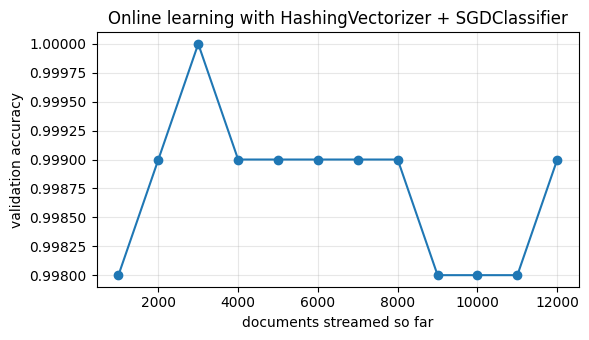

In [19]:
rng = np.random.default_rng(1)

topic_words = {
    0: "goal match team player score league coach season win stadium".split(),
    1: "election vote senate policy minister law party budget campaign tax".split(),
    2: "gpu python model training data neural network compile server kernel".split(),
}
filler = "the a of and to in is that it for on with as was at by".split()

def stream_batches(n_batches=60, batch_size=200):
    # Yields (texts, labels) without holding the full dataset in memory
    for _ in range(n_batches):
        labels = rng.integers(0, 3, size=batch_size)
        batch = []
        for lab in labels:
            n = rng.integers(8, 16)
            w = [rng.choice(topic_words[lab]) if rng.random() < 0.45 else rng.choice(filler) for _ in range(n)]
            # a few random rare tokens simulate an ever-growing vocabulary
            w += [f"tok{rng.integers(0, 10**6)}" for _ in range(2)]
            batch.append(" ".join(w))
        yield batch, labels

hasher = HashingVectorizer(n_features=2**16, alternate_sign=True, norm="l2")
sgd = SGDClassifier(loss="log_loss", random_state=0)
classes = np.array([0, 1, 2])

# fixed held-out set
X_val_txt, y_val = next(stream_batches(n_batches=1, batch_size=1000))
X_val = hasher.transform(X_val_txt)

history = []
for i, (txt, lab) in enumerate(stream_batches(), start=1):
    sgd.partial_fit(hasher.transform(txt), lab, classes=classes)
    if i % 5 == 0:
        history.append((i * 200, accuracy_score(y_val, sgd.predict(X_val))))

hist = pd.DataFrame(history, columns=["docs_seen", "val_accuracy"])
print(hist.tail())

plt.figure(figsize=(6, 3.5))
plt.plot(hist.docs_seen, hist.val_accuracy, marker="o")
plt.xlabel("documents streamed so far"); plt.ylabel("validation accuracy")
plt.title("Online learning with HashingVectorizer + SGDClassifier")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

Each batch contained brand-new random tokens (`tok123456`...). A vocabulary-based vectorizer would have to grow or ignore them; the hashing vectorizer handles them with no extra memory.

## 10. `FeatureHasher` for non-text features

In [20]:
records = [
    {"city": "Nagpur", "device": "mobile", "clicks": 3},
    {"city": "Pune",   "device": "desktop", "clicks": 1},
    {"city": "Nagpur", "device": "desktop", "clicks": 7},
]
fh = FeatureHasher(n_features=16, input_type="dict", alternate_sign=False)
print(fh.transform(records).toarray())

[[0. 3. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 7. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


## 11. Summary

| Point | Takeaway |
|---|---|
| Core trick | `index = hash(token) mod n_features` (plus a sign bit) |
| Stateless | `transform` works without `fit` |
| Memory | Fixed; no vocabulary stored |
| Trade-off | Collisions and no interpretability |
| `n_features` | Larger means fewer collisions; tune it like a hyperparameter |
| `alternate_sign` | `True` is better for similarity preservation; `False` for `MultinomialNB` |
| Best use | Huge or streaming corpora with `partial_fit` models |

### Exercises

1. Re-run the collision experiment with 50,000 tokens. At what `n_features` does the collision rate fall below 5%?
2. Compare accuracy of `alternate_sign=True` vs `False` on the classification task for `n_features` of 64, 256 and 1024.
3. Add `TfidfTransformer` to the streaming loop. What changes, and why is it awkward in a true streaming setting?